# Mini-project 3: Lake Victoria fish stock & export risk Model

Stock is in tonnes; price is UGX per kg

In [4]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("Open Jupyter in the correct folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.fishery import FishStock, PriceModel, RiskAssessor, annual_revenue_samples

a, b = 0, 1
fib = []
for _ in range(15):
    fib.append(a)
    a, b = b, a+b
print("15 Fibonacci numbers as a naive stock baseline:", fib)

15 Fibonacci numbers as a naive stock baseline: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]


The Fibonacci sequence grows without bound and has no environmental carrying capacity. Fish compete for food and habitat, so reproduction slows as stock approaches an ecological limit. Harvesting removes fish regardless of their reproduction; the Fibonacci rule does not include harvest. It also has no biological units or measured growth rate, so it cannot support sustainable catch decisions.

## Stock, price, and weekly revenue

In [3]:
rng = np.random.default_rng(42)
stock_model = FishStock(initial=4000, growth=.4, capacity=10000, harvest_rate=.1)
stocks, catches = stock_model.simulate(52)
price_model = PriceModel(start=12000, lower=9000, upper=16000)
prices = price_model.simulate(52, rng)
weekly_revenue = catches*1000*prices
# Catch is tonnes but price is per kilogram, so multiply catch by 1,000.
risk = RiskAssessor()
stats = risk.describe(weekly_revenue)
print("First stock after one week, tonnes:", stocks[1])
print("Revenue descriptive statistics, UGX (variance in UGX²):", stats)
print("Risk based on weekly CV:", risk.classify(stats['CV']))
print("The fixed variance threshold 50,000 is arbitrary: rescaling UGX into thousands of UGX changes variance by a million.")
print("Theoretical MSY = rK/4, tonnes per week:", stock_model.maximum_sustainable_yield())

First stock after one week, tonnes: 4560.0
Revenue descriptive statistics, UGX (variance in UGX²): {'mean': 8736915999.399994, 'median': 8930284259.61118, 'variance': 1.1774432225768422e+18, 'std_dev': 1085100558.739531, 'CV': 0.12419720629270672}
Risk based on weekly CV: low
The fixed variance threshold 50,000 is arbitrary: rescaling UGX into thousands of UGX changes variance by a million.
Theoretical MSY = rK/4, tonnes per week: 1000.0


## Scenarios and annual downside risk

For each harvest rate use one fixed-seed demonstration path to compare total revenue. The 5th percentile of 1,200 simulated annual revenue outcomes is a **lower-tail revenue quantile**, a 5% revenue-at-risk figure. It is not a maximum loss or a guarantee.

In [5]:
scenarios = {}
rows = []
for h in [.05, .10, .20, .30]:
    model = FishStock(harvest_rate=h)
    path, harvest = model.simulate(52)
    revenue = harvest*1000*PriceModel().simulate(52, np.random.default_rng(42))
    distribution = annual_revenue_samples(harvest, PriceModel(), repeats=1200, seed=2026)
    scenarios[h] = (path, harvest, distribution)
    rows.append({"harvest rate":h, "final stock (tonnes)":path[-1],
                 "total revenue (UGX)":revenue.sum(),
                 "weekly CV":risk.describe(revenue)['CV'],
                 "risk class":risk.classify(risk.describe(revenue)['CV']),
                 "annual 5th percentile (UGX)":np.percentile(distribution,5)})
scenario_table = pd.DataFrame(rows).set_index('harvest rate')
print(scenario_table.round(2).to_string())
print("MSY is a long-run harvest RATE at N=K/2, not an automatic 52-week quota from the 4,000-tonne starting stock.")

              final stock (tonnes)  total revenue (UGX)  weekly CV risk class  annual 5th percentile (UGX)
harvest rate                                                                                              
0.05                       8750.00         2.640473e+11       0.14        low                 2.230083e+11
0.10                       7500.00         4.543196e+11       0.12        low                 3.839348e+11
0.20                       4999.99         6.183067e+11       0.07        low                 5.240935e+11
0.30                       2503.72         5.145373e+11       0.11        low                 4.418549e+11
MSY is a long-run harvest RATE at N=K/2, not an automatic 52-week quota from the 4,000-tonne starting stock.


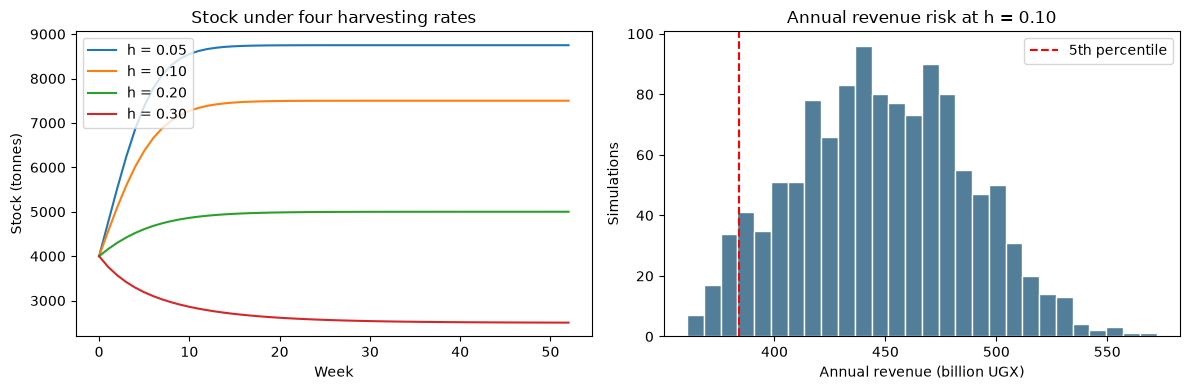

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for h, (path, _, _) in scenarios.items():
    axes[0].plot(range(53), path, label=f"h = {h:.2f}")
axes[0].set(xlabel="Week", ylabel="Stock (tonnes)", title="Stock under four harvesting rates")
axes[0].legend()
distribution = scenarios[.10][2]
cutoff = np.percentile(distribution, 5)
axes[1].hist(distribution/1e9, bins=28, color="#527e99", edgecolor="white")
axes[1].axvline(cutoff/1e9, color="red", linestyle="--", label="5th percentile")
axes[1].set(xlabel="Annual revenue (billion UGX)", ylabel="Simulations",
            title="Annual revenue risk at h = 0.10")
axes[1].legend()
fig.tight_layout()
plt.show()

## Findings & Limitations

The stock model limits growth as fish approach the carrying capacity, unlike the unbounded Fibonacci baseline. The four scenario rows show that increasing the harvest fraction initially raises weekly catch but also changes the subsequent stock path. The theoretical logistic MSY is rK/4 = 1,000 tonnes per week at a stock of 5,000 tonnes; it is an equilibrium benchmark, not a promise of sustained annual output from a starting stock of 4,000 tonnes. Consequently, judge each scenario by its end-of-year stock as well as its revenue. A price-driven high-revenue path can still draw down the biological resource.

The sample variance of weekly revenue has units UGX². A rule that flags a variance above 50,000 is meaningless without specifying units, scale and a decision threshold. CV instead divides the weekly standard deviation by mean revenue; the explicit bands used here are illustrative (low below 0.15, moderate below 0.30, high otherwise). Price uncertainty is represented by 1,200 seeded, bounded random-walk paths. The plotted 5th percentile indicates that about 5% of outcomes in this simplified simulation fall below that annual revenue level, not that losses stop there.

This is a single-species stock with constant r, K and fishing effort, no migration or illegal catch, and a stylized price process. CV mixes changes in the harvest trajectory and price movements. Actual cooperative decisions would need measured catch-per-unit-effort, stock assessments, seasonal rules, costs and export prices.